In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [ ]:
df = pd.read_csv("Country-data.csv")

In [ ]:
print(df.shape)

(167, 10)


In [ ]:
df.describe()

,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
count,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000
mean,38.270060,41.108976,6.815689,46.890215,17144.688623,7.781832,70.555689,2.947964,12964.155689
std,40.328931,27.412010,2.746837,24.209589,19278.067698,10.570704,8.893172,1.513848,18328.704809
min,2.600000,0.109000,1.810000,0.065900,609.000000,-4.210000,32.100000,1.150000,231.000000
25%,8.250000,23.800000,4.920000,30.200000,3355.000000,1.810000,65.300000,1.795000,1330.000000
50%,19.300000,35.000000,6.320000,43.300000,9960.000000,5.390000,73.100000,2.410000,4660.000000
75%,62.100000,51.350000,8.600000,58.750000,22800.000000,10.750000,76.800000,3.880000,14050.000000
max,208.000000,200.000000,17.900000,174.000000,125000.000000,104.000000,82.800000,7.490000,105000.000000


In [ ]:
df.isnull().sum()

,0
country,0
child_mort,0
exports,0
health,0
imports,0
income,0
inflation,0
life_expec,0
total_fer,0
gdpp,0


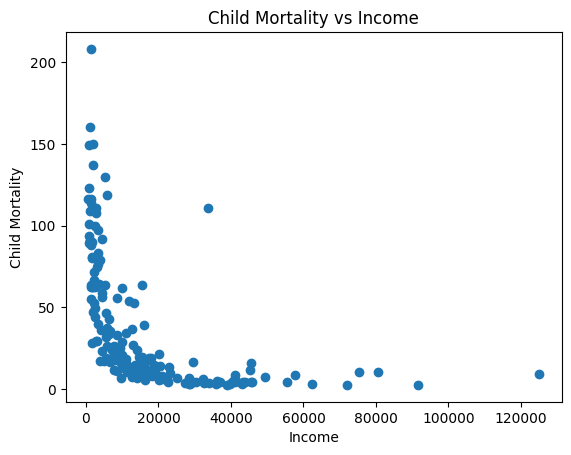

In [ ]:
plt.scatter(df["income"], df["child_mort"])
plt.xlabel("Income")
plt.ylabel("Child Mortality")
plt.title("Child Mortality vs Income")
plt.show()

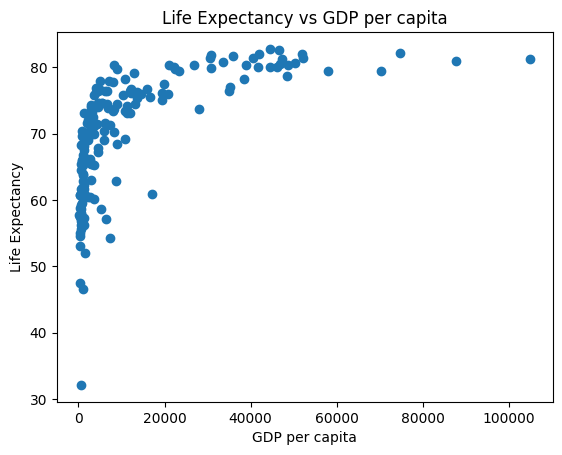

In [ ]:
plt.scatter(df["gdpp"], df["life_expec"])
plt.xlabel("GDP per capita")
plt.ylabel("Life Expectancy")
plt.title("Life Expectancy vs GDP per capita")
plt.show()

In [ ]:
features = df.drop("country", axis=1)
scaler = StandardScaler()
scaled_features = scaler.fit_transform(features)

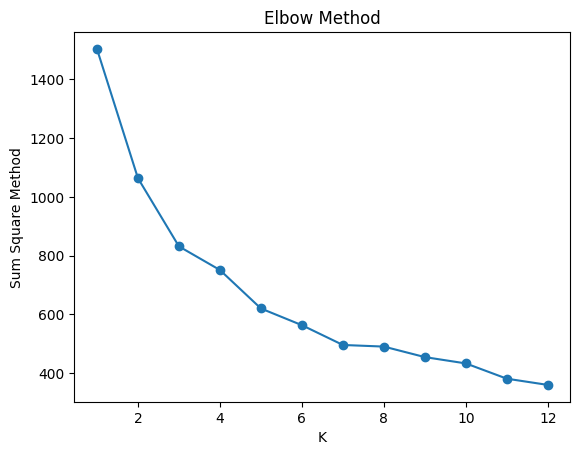

In [ ]:
sum_sq_error = []
for k in range(1, 13):
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(scaled_features)
    sum_sq_error.append(kmeans.inertia_)

plt.plot(range(1, 13), sum_sq_error, marker='o')
plt.xlabel("K")
plt.ylabel("Sum Square Method")
plt.title("Elbow Method")
plt.show()

K = 2 -> Silhouette Score = 0.2663
K = 3 -> Silhouette Score = 0.2856
K = 4 -> Silhouette Score = 0.288
K = 5 -> Silhouette Score = 0.3009
K = 6 -> Silhouette Score = 0.2357
K = 7 -> Silhouette Score = 0.2479
K = 8 -> Silhouette Score = 0.202
K = 9 -> Silhouette Score = 0.1923
K = 10 -> Silhouette Score = 0.1962


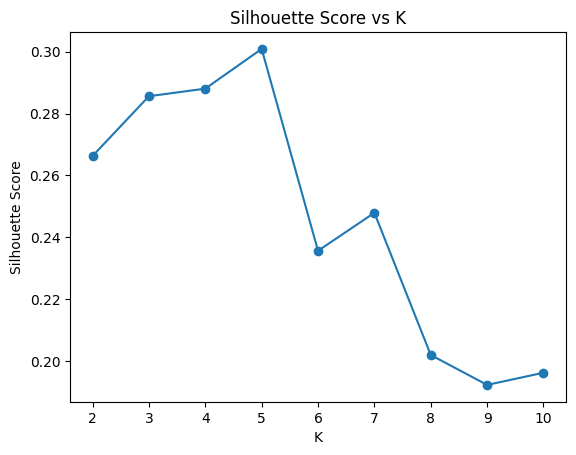

In [ ]:
sil_scores = []
for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(scaled_features)
    score = silhouette_score(scaled_features, labels)
    sil_scores.append(score)
    print("K =", k, "-> Silhouette Score =", round(score, 4))

plt.plot(range(2, 11), sil_scores, marker='o')
plt.xlabel("K")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score vs K")
plt.show()

In [ ]:
kmeans = KMeans(n_clusters=3, random_state=42)
df["Cluster"] = kmeans.fit_predict(scaled_features)
df.head()

,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp,Cluster
0,Afghanistan,90.2,10.0,7.58,44.9,1610,9.44,56.2,5.82,553,2
1,Albania,16.6,28.0,6.55,48.6,9930,4.49,76.3,1.65,4090,0
2,Algeria,27.3,38.4,4.17,31.4,12900,16.10,76.5,2.89,4460,0
3,Angola,119.0,62.3,2.85,42.9,5900,22.40,60.1,6.16,3530,2
4,Antigua and Barbuda,10.3,45.5,6.03,58.9,19100,1.44,76.8,2.13,12200,0


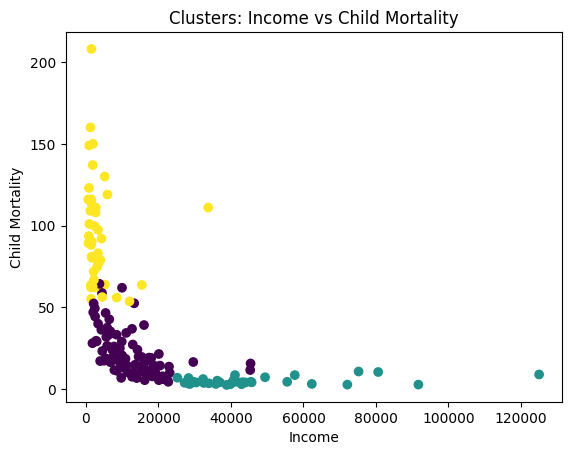

In [ ]:
plt.scatter(df["income"], df["child_mort"], c=df["Cluster"])
plt.xlabel("Income")
plt.ylabel("Child Mortality")
plt.title("Clusters: Income vs Child Mortality")
plt.show()

In [ ]:
plt.scatter(df["income"], df["life_expec"], c=df["Cluster"])
plt.xlabel("Income")
plt.ylabel("Life Expectancy")
plt.title("Clusters: Income vs Life Expectancy")
plt.show()

In [ ]:
cluster_profile = df.groupby("Cluster")[features.columns].mean()
cluster_profile

,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
Cluster,,,,,,,,,
0,22.456977,40.273128,6.251047,47.362394,12321.744186,7.720884,72.566279,2.340349,6461.767442
1,5.000000,58.738889,8.807778,51.491667,45672.222222,2.671250,80.127778,1.752778,42494.444444
2,95.106667,28.602444,6.301111,42.306667,3539.844444,11.986778,59.055556,5.065333,1766.711111


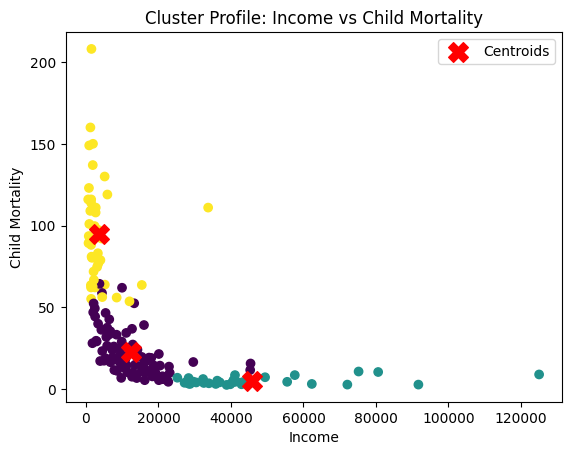

In [ ]:
centers = scaler.inverse_transform(kmeans.cluster_centers_)

plt.scatter(df["income"], df["child_mort"], c=df["Cluster"])
plt.scatter(centers[:,4], centers[:,0], c="red", marker="X", s=200, label="Centroids")
plt.xlabel("Income")
plt.ylabel("Child Mortality")
plt.title("Cluster Profile: Income vs Child Mortality")
plt.legend()
plt.show()

In [ ]:
sorted_clusters = cluster_profile.sort_values("income").index.tolist()

df["Development_Status"] = df["Cluster"].map({
    sorted_clusters[0]: "Underdeveloped",
    sorted_clusters[1]: "Developing",
    sorted_clusters[2]: "Developed"
})

df[["country", "Cluster", "Development_Status"]].head()

,country,Cluster,Development_Status
0,Afghanistan,2,Underdeveloped
1,Albania,0,Developing
2,Algeria,0,Developing
3,Angola,2,Underdeveloped
4,Antigua and Barbuda,0,Developing


In [ ]:
underdeveloped = df[df["Development_Status"] == "Underdeveloped"]
underdeveloped_sorted = underdeveloped.sort_values("income")
underdeveloped_sorted[["country", "child_mort", "income", "life_expec", "gdpp"]].head(10)

,country,child_mort,income,life_expec,gdpp
136,Solomon Islands,28.1,1780,61.7,1290
109,Nepal,47.0,1990,68.3,592
146,Tajikistan,52.4,2110,69.6,738
12,Bangladesh,49.4,2440,70.4,758
27,Cambodia,44.4,2520,66.1,786
83,Kyrgyz Republic,29.6,2790,68.5,880
162,Vanuatu,29.2,2950,63.0,2970
101,"Micronesia, Fed. Sts.",40.0,3340,65.4,2860
107,Myanmar,64.4,3720,66.8,988
102,Moldova,17.2,3910,69.7,1630
